# №3. Автоконтрастирование с отсечением выбросов

Проверяем устойчивость к ярким выбросам, растягиваем выбранный диапазон и приводим среднюю яркость к заданному значению. Параметры `p` и `q` задаются в процентах.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

rng = np.random.default_rng(42)

In [3]:
rgb = np.array(Image.open('data/scene.jpg').convert('RGB'))
gray = rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722])

## 1. Автоконтраст по самым тёмным 99% пикселей

Сортируем пиксели по яркости и оставляем ровно $k=\lfloor0.99N\rfloor$ элементов. Для совпадающих значений порядок задаёт их позиция в массиве (`stable`-сортировка).

Берём максимум оставшейся группы $M$ и множитель $a=255/M$. Умножаем весь кадр. Значения выше $M$ попадают в белый уровень 255. Для группы с максимумом 0 используем $a=1$.


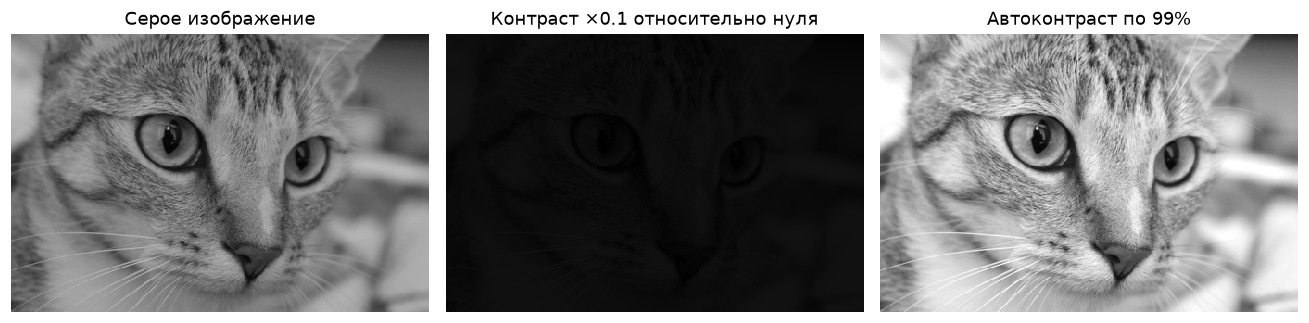

Пикселей: 135300; в группе: 133947
Максимум группы: 17.918; множитель: 14.232


In [4]:
def darkest_indices(image, q=1):
    """Индексы самых тёмных (100-q)% элементов массива."""
    flat = image.ravel()
    count = int(flat.size * (1 - q / 100))
    return np.argsort(flat, kind='stable')[:count]


def auto_darkest(image, q=1):
    array = image.astype(float)
    indices = darkest_indices(array, q)
    maximum = array.ravel()[indices].max()
    factor = 255 / maximum if maximum > 0 else 1.0
    return np.clip(array * factor, 0, 255), factor, maximum


dark = gray / 10
clean_result, clean_factor, clean_maximum = auto_darkest(dark, q=1)
show_images([to_uint8(gray), to_uint8(dark), to_uint8(clean_result)],
            ['Серое изображение', 'Контраст ×0.1 относительно нуля', 'Автоконтраст по 99%'], cols=3)
print(f'Пикселей: {gray.size}; в группе: {darkest_indices(dark).size}')
print(f'Максимум группы: {clean_maximum:.3f}; множитель: {clean_factor:.3f}')

### Рост числа импульсных выбросов

Выбираем $n$ разных координат и заменяем значения случайными целыми числами от 0 до 255. Это импульсный шум со случайной амплитудой. У варианта «соль/перец» амплитуды принимают только 0 и 255.

Для разных $n$ используем вложенные наборы координат и одинаковые значения шума. Так рост числа выбросов становится единственной меняющейся частью опыта. Ошибку считаем по сохранившимся чистым пикселям относительно результата на чистом кадре. За заметную деградацию принимаем падение множителя ниже 80% его чистого значения.


Шум, %      n     максимум 99%  множитель   MAE чистых пикселей
   0.0       0         17.918     14.232               0.000
   0.1     135         18.003     14.165               0.774
   0.5     676         18.396     13.862               4.285
   1.0    1353         18.975     13.439               9.228
   1.2    1624         40.000      6.375              92.136
   1.5    2030         84.000      3.036             131.331
   2.0    2706        127.000      2.008             143.396
   5.0    6765        204.000      1.250             152.274
  10.0   13530        230.000      1.109             153.946


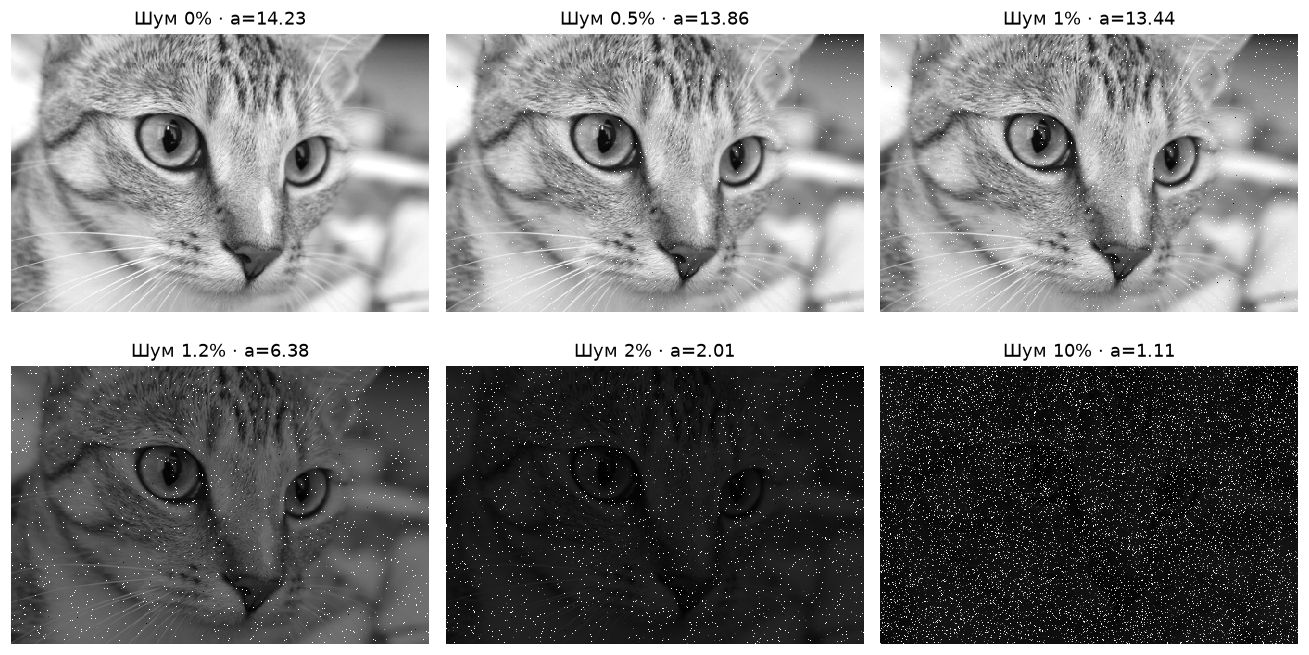

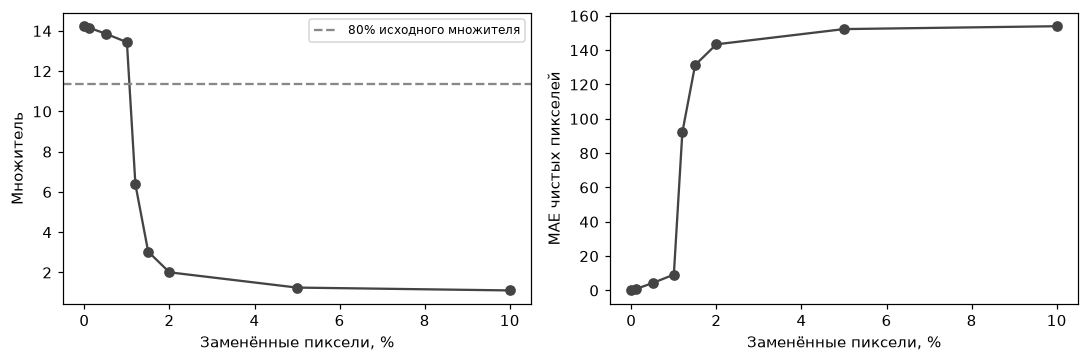

Первый проверенный уровень заметной деградации: 1.2%, n=1624.
При случайной амплитуде часть выбросов остаётся внутри исходного диапазона.
Поэтому граница устойчивости зависит от амплитуд и яркостей кадра.


In [5]:
fractions = np.array([0, 0.1, 0.5, 1.0, 1.2, 1.5, 2.0, 5.0, 10.0])
order = rng.permutation(dark.size)
noise_values = rng.integers(0, 256, dark.size)
records = []
examples = []

for percent in fractions:
    n = int(round(percent / 100 * dark.size))
    noisy = dark.copy().ravel()
    noisy[order[:n]] = noise_values[:n]
    noisy = noisy.reshape(dark.shape)
    restored, factor, maximum = auto_darkest(noisy, q=1)
    clean_mask = np.ones(dark.size, dtype=bool)
    clean_mask[order[:n]] = False
    error = np.abs(restored.ravel()[clean_mask] - clean_result.ravel()[clean_mask]).mean()
    records.append((percent, n, maximum, factor, error))
    if percent in (0, 0.5, 1.0, 1.2, 2.0, 10.0):
        examples.append((restored, f'Шум {percent:g}% · a={factor:.2f}'))

print('Шум, %      n     максимум 99%  множитель   MAE чистых пикселей')
for percent, n, maximum, factor, error in records:
    print(f'{percent:6.1f} {n:7d} {maximum:14.3f} {factor:10.3f} {error:19.3f}')
show_images([to_uint8(item[0]) for item in examples], [item[1] for item in examples], cols=3)

records_array = np.array(records)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(records_array[:, 0], records_array[:, 3], 'o-', color='#444444')
axes[0].axhline(0.8 * clean_factor, color='#888888', linestyle='--', label='80% исходного множителя')
axes[0].set(xlabel='Заменённые пиксели, %', ylabel='Множитель')
axes[0].legend(fontsize=8)
axes[1].plot(records_array[:, 0], records_array[:, 4], 'o-', color='#444444')
axes[1].set(xlabel='Заменённые пиксели, %', ylabel='MAE чистых пикселей')
fig.tight_layout()
plt.show()

failed = [row for row in records if row[3] < 0.8 * clean_factor]
if failed:
    first = failed[0]
    print(f'Первый проверенный уровень заметной деградации: {first[0]:g}%, n={first[1]}.')
print('При случайной амплитуде часть выбросов остаётся внутри исходного диапазона.')
print('Поэтому граница устойчивости зависит от амплитуд и яркостей кадра.')

### Сравнение со «солью/перцем»

При тех же координатах отдельно подставляем значения 0 и 255 с равными вероятностями. Половина таких выбросов в среднем попадает в белый уровень. Отсечение верхнего 1% защищает от этой части шума; чёрные точки остаются в изображении.


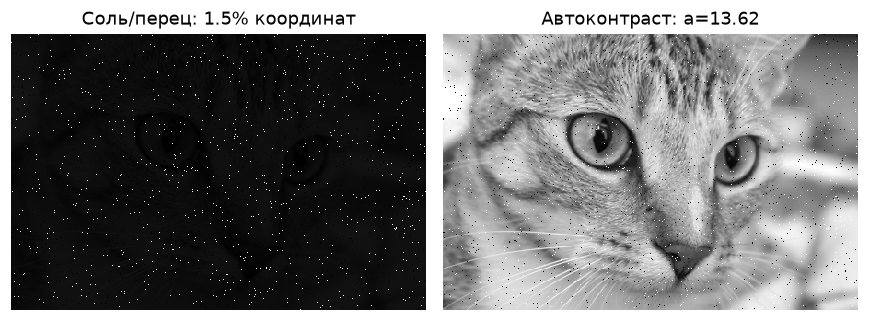

In [6]:
n = int(round(0.015 * dark.size))
salt_pepper = dark.copy().ravel()
salt_pepper[order[:n]] = rng.choice([0, 255], size=n)
salt_pepper = salt_pepper.reshape(dark.shape)
salt_result, salt_factor, _ = auto_darkest(salt_pepper)
show_images([to_uint8(salt_pepper), to_uint8(salt_result)],
            ['Соль/перец: 1.5% координат', f'Автоконтраст: a={salt_factor:.2f}'], cols=2)

## 2. Отсечение p% тёмных и q% светлых пикселей

Вычисляем границы $L=P_p(I)$ и $H=P_{100-q}(I)$, затем

$$I'=\operatorname{clip}\left(255\frac{I-L}{H-L},0,255\right).$$

`np.percentile` использует линейную интерполяцию между соседними отсортированными значениями. Пиксели ниже $L$ становятся чёрными, выше $H$ — белыми. Для постоянного массива сохраняем исходный уровень.

Для RGB сравниваем общие границы по всем каналам с отдельными границами для R, G и B. Поканальное растяжение меняет баланс цветов.


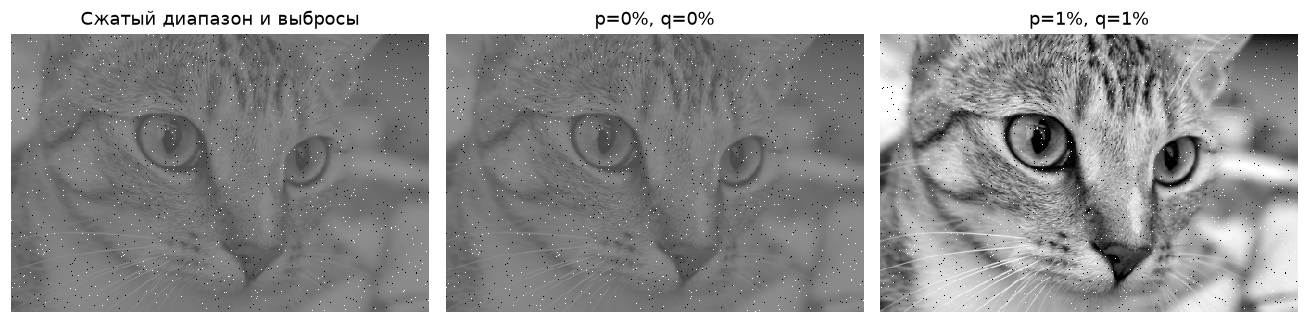

Выбранный диапазон: [77.615, 143.699]


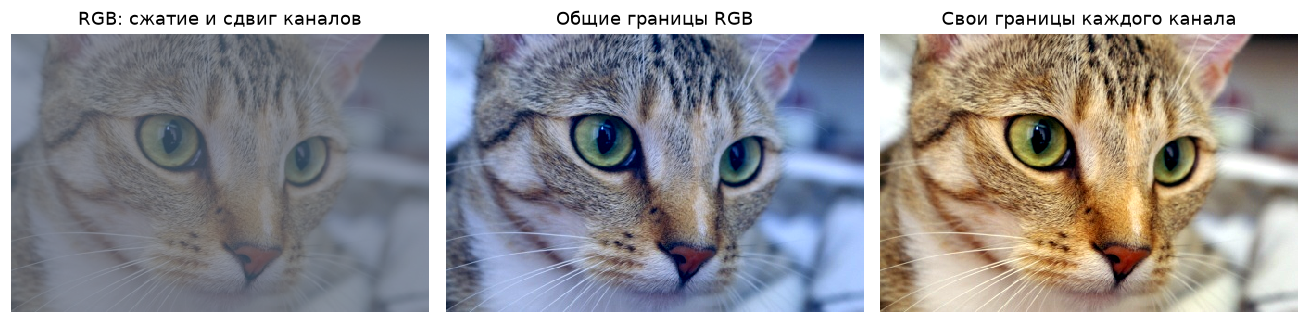

Нижние границы R, G, B: [63.9  75.35 88.15]
Верхние границы R, G, B: [135.45 143.75 163.3 ]


In [7]:
def auto_percentiles(image, p=1, q=1, per_channel=False):
    array = image.astype(float)
    axis = (0, 1) if per_channel else None
    low, high = np.percentile(array, [p, 100 - q], axis=axis)
    span = high - low
    factor = np.divide(255.0, span, out=np.ones_like(span, dtype=float), where=span > 0)
    offset = np.where(span > 0, low, 0.0)
    return np.clip((array - offset) * factor, 0, 255), low, high


low_contrast = 70 + 0.4 * gray
flat = low_contrast.copy().ravel()
flat[order[:int(0.005 * flat.size)]] = 0
flat[order[int(0.005 * flat.size):int(0.01 * flat.size)]] = 255
low_contrast = flat.reshape(gray.shape)
classic, _, _ = auto_percentiles(low_contrast, p=0, q=0)
robust, low, high = auto_percentiles(low_contrast, p=1, q=1)
show_images([to_uint8(low_contrast), to_uint8(classic), to_uint8(robust)],
            ['Сжатый диапазон и выбросы', 'p=0%, q=0%', 'p=1%, q=1%'], cols=3)
print(f'Выбранный диапазон: [{low:.3f}, {high:.3f}]')

colored = np.clip(0.45 * rgb.astype(float) + np.array([45, 65, 85]), 0, 255)
shared, _, _ = auto_percentiles(colored, p=1, q=1)
separate, low_rgb, high_rgb = auto_percentiles(colored, p=1, q=1, per_channel=True)
show_images([to_uint8(colored), to_uint8(shared), to_uint8(separate)],
            ['RGB: сжатие и сдвиг каналов', 'Общие границы RGB', 'Свои границы каждого канала'], cols=3)
print('Нижние границы R, G, B:', np.round(low_rgb, 2))
print('Верхние границы R, G, B:', np.round(high_rgb, 2))

## 3. Средняя яркость оставшейся группы равна 128

Оставляем самые тёмные $(100-q)\%$ пикселей и вычисляем их среднее $m$. Множитель $a=128/m$ даёт среднее 128 **до насыщения**. После ограничения 0–255 среднее может уменьшиться. Печатаем обе величины, чтобы проследить этот эффект.

Для полностью чёрной группы множитель принимаем равным 1; исходный нулевой уровень сохраняется.


q, %   множитель   среднее до clip   среднее после clip
   0      10.906            128.000              128.000
   1      10.969            128.000              128.000
   5      11.192            128.000              128.000
  10      11.456            128.000              128.000


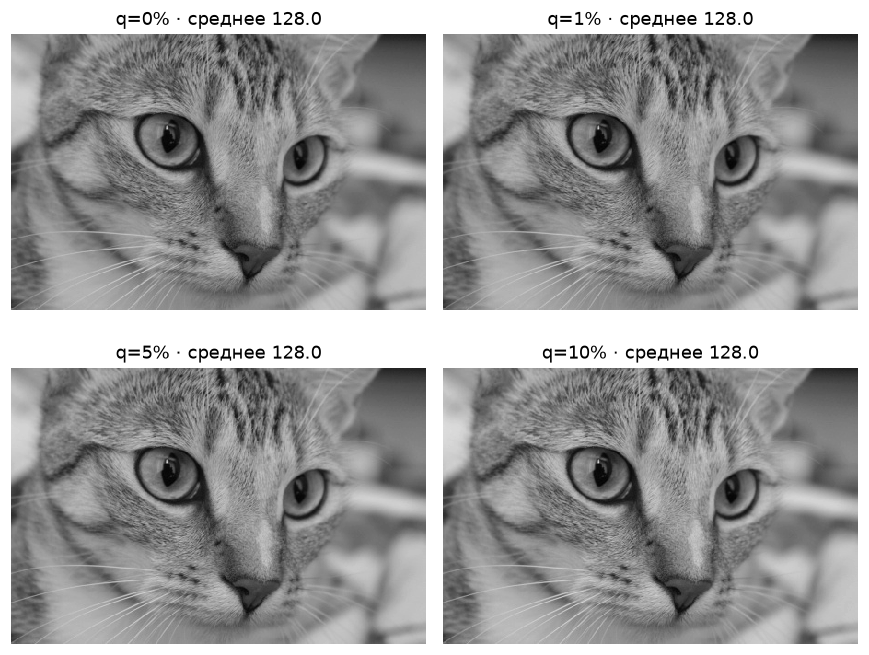

Тёмный фон: a=16.14, среднее до clip=128.00, после clip=49.92


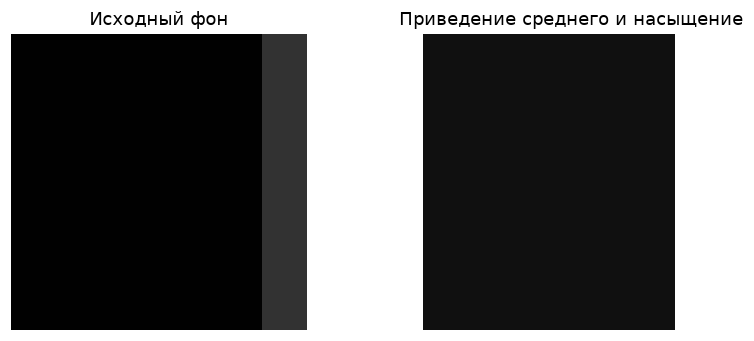

In [8]:
def auto_mean(image, q=1, target=128):
    array = image.astype(float)
    indices = darkest_indices(array, q)
    mean = array.ravel()[indices].mean()
    factor = target / mean if mean > 0 else 1.0
    raw = array * factor
    clipped = np.clip(raw, 0, 255)
    return clipped, factor, raw.ravel()[indices].mean(), clipped.ravel()[indices].mean()


print('q, %   множитель   среднее до clip   среднее после clip')
mean_results = []
for q in [0, 1, 5, 10]:
    result, factor, before, after = auto_mean(dark, q=q)
    mean_results.append((result, f'q={q}% · среднее {after:.1f}'))
    print(f'{q:4d} {factor:11.3f} {before:18.3f} {after:20.3f}')
show_images([to_uint8(x[0]) for x in mean_results], [x[1] for x in mean_results], cols=2)

# Дополнительный пример с большой долей тёмного фона.
skewed = np.ones((100, 100))
skewed[:, 85:] = 50
result, factor, before, after = auto_mean(skewed, q=1)
print(f'Тёмный фон: a={factor:.2f}, среднее до clip={before:.2f}, после clip={after:.2f}')
show_images([to_uint8(skewed), to_uint8(result)], ['Исходный фон', 'Приведение среднего и насыщение'], cols=2)

## Вывод

Отсечение верхнего 1% удерживает коэффициент близким к чистому значению, пока яркие выбросы помещаются в отбрасываемую группу. После пересечения этой границы выбранный максимум растёт, множитель падает, изображение остаётся тёмным. Таблица показывает первый проверенный уровень деградации для фиксированного зерна и выбранного кадра.

Две процентильные границы одновременно задают множитель и слагаемое. Их поканальный расчёт также корректирует баланс RGB. Приведение среднего к 128 точно выполняется для исходного результата умножения; насыщение верхних значений уменьшает итоговое среднее.
